# Deep Q-Learning on CartPole and LunarLander

DQN, Double DQN, and a generalized Double DQN agent. Stored outputs are historical; default execution performs only smoke checks. [Research record](../docs/research-notes.md).

In [ ]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from agents import DQN, DoubleDQN, GeneralDoubleDQN
from experiments import run_experiment, smoke_check
SMOKE_TEST = True  # One minibatch epoch per agent; never run full training by default.
MAX_EPISODES = 1000  # Explicit cap used only when SMOKE_TEST=False.


In [35]:
import gymnasium as gym
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

This notebook retains the three experiments from the original undergraduate project. See [course context](../docs/course-context.md) for provenance of the supplied teaching examples.

## CartPole: DQN

Historical training curves and logs follow. A smoke check validates execution only and does not establish a solved environment.

In [36]:
env = gym.make("CartPole-v1")

In [37]:
# DQN is imported from src/agents.py; architecture and update rule are preserved.


In [38]:
env = gym.make("CartPole-v1")
agent = DQN(
    gamma=0.99, epsilon_start=1.0, epsilon_min=0.01, epsilon_max=1.0,
    epsilon_interval=0.99, batch_size=64, max_memory_length=50_000,
    pure_exploration_episodes=30, epsilon_greedy_episodes=500,
    num_actions=2,
)
try:
    if SMOKE_TEST:
        smoke_check(agent, env)
        running_reward_history = []  # Smoke checks are not learning curves.
    else:
        running_reward_history = run_experiment(
            agent, env, max_episodes=MAX_EPISODES, update_target_every=125,
            solve_threshold=220, output=ROOT / "results/rerun/cartpole_dqn.csv",
        )
finally:
    env.close()


Historical run: 527 logged episodes. Final running reward: 223.60.
Full log: ../results/cartpole_dqn_original_log.txt


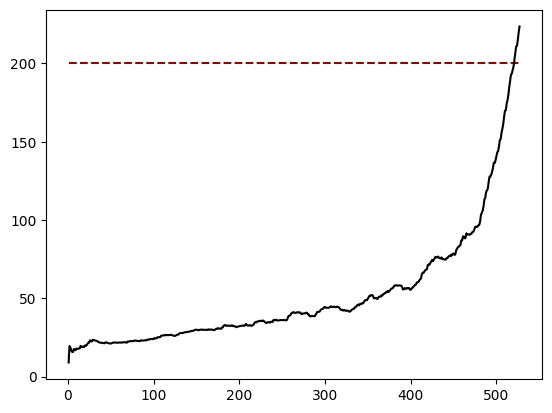

In [39]:
if not SMOKE_TEST:
    import matplotlib.pyplot as plt
    import seaborn as sns

    yy = np.array(running_reward_history)
    xx = np.arange(1, len(yy) + 1)

    fig = plt.figure()
    ax = sns.lineplot(
        x=xx,
        y=200,
        color="darkred",
        linestyle="dashed"
    )
    ax = sns.lineplot(
        x=xx,
        y=yy,
        color="black"
    )
    plt.show()

## CartPole: Double DQN

Historical training curves and logs follow. A smoke check validates execution only and does not establish a solved environment.

In [ ]:
# DoubleDQN is imported from src/agents.py; architecture and update rule are preserved.


In [9]:
env = gym.make("CartPole-v1")
agent = DoubleDQN(
    gamma=0.99, epsilon_start=1.0, epsilon_min=0.01, epsilon_max=1.0,
    epsilon_interval=0.99, batch_size=64, max_memory_length=50_000,
    pure_exploration_episodes=30, epsilon_greedy_episodes=500,
    num_actions=2,
)
try:
    if SMOKE_TEST:
        smoke_check(agent, env)
        running_reward_history = []  # Smoke checks are not learning curves.
    else:
        running_reward_history = run_experiment(
            agent, env, max_episodes=MAX_EPISODES, update_target_every=125,
            solve_threshold=220, output=ROOT / "results/rerun/cartpole_ddqn.csv",
        )
finally:
    env.close()


Historical run: 460 logged episodes. Final running reward: 66.06.
Full log: ../results/cartpole_ddqn_original_log.txt
Interrupted before solving.


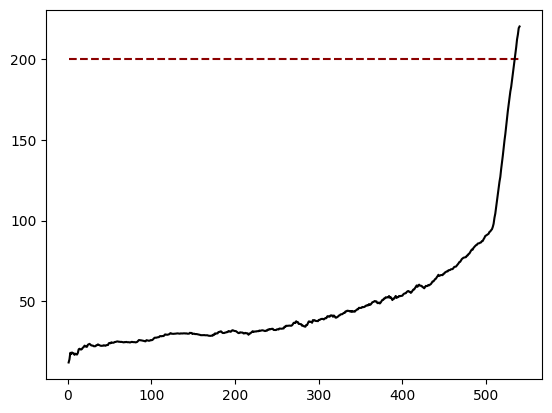

In [35]:
if not SMOKE_TEST:
    import matplotlib.pyplot as plt
    import seaborn as sns

    yy = np.array(running_reward_history)
    xx = np.arange(1, len(yy) + 1)

    fig = plt.figure()
    ax = sns.lineplot(
        x=xx,
        y=200,
        color="darkred",
        linestyle="dashed"
    )
    ax = sns.lineplot(
        x=xx,
        y=yy,
        color="black"
    )
    plt.show()

## LunarLander: generalized Double DQN

Historical training curves and logs follow. A smoke check validates execution only and does not establish a solved environment.

In [29]:
# GeneralDoubleDQN is imported from src/agents.py; architecture and update rule are preserved.


In [32]:
env = gym.make("LunarLander-v3")
agent = GeneralDoubleDQN(
    gamma=0.99, epsilon_start=1.0, epsilon_min=0.01, epsilon_max=1.0,
    epsilon_interval=0.99, batch_size=128, max_memory_length=50_000,
    pure_exploration_episodes=20, epsilon_greedy_episodes=500,
    env=env,
)
try:
    if SMOKE_TEST:
        smoke_check(agent, env)
        running_reward_history = []  # Smoke checks are not learning curves.
    else:
        running_reward_history = run_experiment(
            agent, env, max_episodes=MAX_EPISODES, update_target_every=250,
            solve_threshold=200, output=ROOT / "results/rerun/lunarlander_ddqn.csv",
        )
finally:
    env.close()


Historical run: 590 logged episodes. Final running reward: 201.60.
Full log: ../results/lunarlander_ddqn_original_log.txt


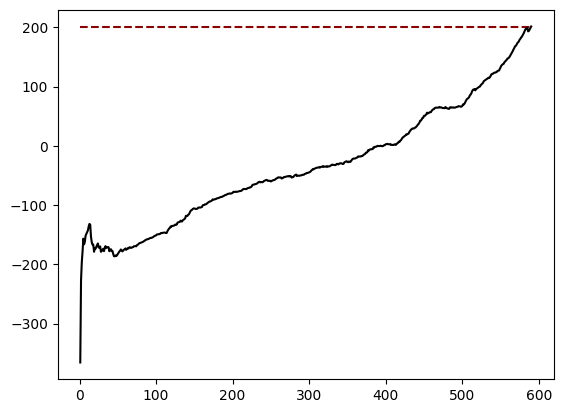

In [33]:
if not SMOKE_TEST:
    import matplotlib.pyplot as plt
    import seaborn as sns

    yy = np.array(running_reward_history)
    xx = np.arange(1, len(yy) + 1)

    fig = plt.figure()
    ax = sns.lineplot(
        x=xx,
        y=200,
        color="darkred",
        linestyle="dashed"
    )
    ax = sns.lineplot(
        x=xx,
        y=yy,
        color="black"
    )
    plt.show()

## Notes

1. Training the agents and adjusting their hyperparameters takes quite a lot of time, so plan well.
2. As a rule of thumb, use neural networks with at least two hidden layers with at least 64 nodes each.
3. A learning rate between $10^{-3}$ and $10^{-4}$ for the neural networks should work reasonably well in most cases.
4. Linearly decaying $\epsilon$ from 1.0 to 0.01 in 500 episodes should work reasonably well in most cases.